In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# === Parameters ===
# Tickers are stock data indices
#tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "TSLA"] # Magnificent Seven
tickers = ["WBD", "PARA", "APA", "WBA", "PCG", "VTRS", "LYB"]        # Worst Seven
equal_weight = 1 / len(tickers)
V0 = 10000 # Initial portfolio investment

In [3]:
# === Download data, normalise and compute Returns  ===
data = yf.download(tickers, period="10y", interval="1d", auto_adjust=False)["Close"] # Historical data
data = data.dropna()  # Drop rows with missing data
daily_returns = data.pct_change().dropna() # Compute daily returns
normalized = data / data.iloc[0] # Normalize prices for BAH portfolio theta weights

[*********************100%***********************]  7 of 7 completed


In [4]:
# === Create series of theta values for BAH portfolio  ===
theta = normalized.shift(1).div(normalized.shift(1).sum(axis=1), axis=0)
# === Create series of theta weights for the rebalanced portfolio  ===
crp_weights = np.array([equal_weight] * len(tickers))

In [5]:
# === Base Strategy Classes ===
class BuyAndHoldStrategy:
    def __init__(self, data, V0):
        self.data = data  # Historical price data
        self.V0 = V0      # Initial investment amount

    def run(self):
        # Normalize prices to initial values
        normalized = self.data / self.data.iloc[0]
        # Calculate portfolio value with equal initial weights
        values = (normalized * equal_weight).sum(axis=1) * self.V0
        # Calculate historical weight evolution
        weights = normalized.shift(1).div(normalized.shift(1).sum(axis=1), axis=0)
        return values, weights.fillna(0)

In [6]:
class ConstantRebalancedStrategy:
    def __init__(self, data, returns, crp_weights, V0, tc_rate=0.001):
        self.data = data               # Historical price data
        self.returns = returns         # Daily returns data
        self.crp_weights = crp_weights # Equal weights for CRP
        self.V0 = V0                   # Initial investment amount
        self.tc_rate = tc_rate         # Transaction cost rate

    def run(self):
        values = [self.V0]
        n_assets = len(self.crp_weights)
        
        # Store weights at each time step
        weights_history = [self.crp_weights.copy()]
        
        # Start with target weights
        current_weights = np.array(self.crp_weights)
        current_values = self.V0 * current_weights
        
        for t in range(1, len(self.data)):
            # Calculate new asset values after price changes
            new_values = current_values * (1 + self.returns.iloc[t-1].values)
            portfolio_value_before = np.sum(new_values)
            
            # Calculate target values after rebalancing
            target_values = self.crp_weights * portfolio_value_before
            
            # Calculate trades needed (Δ_t^i)
            trades = target_values - new_values
            
            # Calculate transaction costs 
            transaction_costs = 0
            for trade in trades:
                if abs(trade) > 0:
                    # max(0.001 * |Δ_t^i|, 1)
                    cost_i = max(self.tc_rate * abs(trade), 1)
                    transaction_costs += cost_i
            
            # Apply transaction costs
            portfolio_value_after = portfolio_value_before - transaction_costs
            
            # Update current values with the new target values (adjusted for costs)
            current_values = target_values * (portfolio_value_after / portfolio_value_before)
            
            values.append(portfolio_value_after)
            weights_history.append(self.crp_weights.copy())  # Target weights remain constant
        
        # Create a DataFrame for weights with the same index as data
        weights_df = pd.DataFrame(
            weights_history, 
            index=self.data.index,
            columns=self.data.columns
        )
        
        return pd.Series(values, index=self.data.index), weights_df

In [7]:
class MomentumStrategy:
    def __init__(self, data, returns, lookback=252, tc_rate=0.001):
        self.data = data          # Historical price data
        self.returns = returns    # Daily returns data
        self.lookback = lookback  # Lookback period for momentum calculation
        self.tc_rate = tc_rate    # Transaction cost rate

    def run(self):
        # Calculate momentum signal using min-max normalization
        roll_min = self.data.rolling(self.lookback).min()
        roll_max = self.data.rolling(self.lookback).max()
        momentum = (self.data - roll_min) / (roll_max - roll_min)
        
        # Calculate momentum weights (theta equivalent)
        theta_momentum = momentum.div(momentum.sum(axis=1), axis=0).fillna(0)

        values = [V0]  # Track portfolio value over time
        transaction_costs = [0]  # Track cumulative transaction costs

        for t in range(1, len(self.data)):
            if t < self.lookback:
                # Start trade with previous time horizon's values
                values.append(values[-1])
                transaction_costs.append(transaction_costs[-1])
                continue
            
            V_prev = values[-1]
            price_ratio = self.data.iloc[t] / self.data.iloc[t - 1]

            # Calculate trades needed and associated costs
            delta = (theta_momentum.iloc[t] * V_prev) - (theta_momentum.iloc[t - 1] * V_prev * price_ratio)
            cost = delta.abs().apply(lambda x: max(x * self.tc_rate, 1) if x > 0 else 0).sum()
            
            # Calculate portfolio growth from asset returns
            growth = np.dot(theta_momentum.iloc[t], self.returns.iloc[t - 1])
            V_new = (V_prev - cost) * (1 + growth)

            values.append(V_new)
            transaction_costs.append(transaction_costs[-1] + cost)

        return pd.Series(values, index=self.data.index), theta_momentum


In [8]:
class AntiMomentumStrategy:
    def __init__(self, data, returns, lookback=252, tc_rate=0.001):
        self.data = data
        self.returns = returns
        self.lookback = lookback
        self.tc_rate = tc_rate

    def run(self):
        roll_min = self.data.rolling(self.lookback).min()
        roll_max = self.data.rolling(self.lookback).max()
        anti_momentum = (roll_max - self.data) / (roll_max - roll_min)
        theta_anti_momentum = anti_momentum.div(anti_momentum.sum(axis=1), axis=0).fillna(0)

        values = [V0]
        transaction_costs = [0]

        for t in range(1, len(self.data)):
            if t < self.lookback:
                values.append(values[-1])
                transaction_costs.append(transaction_costs[-1])
                continue

            V_prev = values[-1]
            price_ratio = self.data.iloc[t] / self.data.iloc[t - 1]

            delta = (theta_anti_momentum.iloc[t] * V_prev) - (theta_anti_momentum.iloc[t - 1] * V_prev * price_ratio)
            cost = delta.abs().apply(lambda x: max(x * self.tc_rate, 1) if x > 0 else 0).sum()

            growth = np.dot(theta_anti_momentum.iloc[t], self.returns.iloc[t - 1])
            V_new = (V_prev - cost) * (1 + growth)

            values.append(V_new)
            transaction_costs.append(transaction_costs[-1] + cost)

        return pd.Series(values, index=self.data.index), theta_anti_momentum

In [9]:
# === Aggregator Class ===
class StrategyAggregator:
    def __init__(self, strategies):
        self.strategies = strategies  # List of strategy objects to aggregate

    def aggregate(self):
        weights_list = []  # Store weights from each strategy
        values_list = []   # Store values from each strategy
        
        # Run each strategy and collect results
        for strategy in self.strategies:
            V, w = strategy.run()
            values_list.append(V)
            weights_list.append(w)
 
        # Combine results into DataFrames/arrays for processing
        values_df = pd.concat(values_list, axis=1)
        weights_stack = np.stack([w.values for w in weights_list])
        values_array = values_df.values

        # Calculate aggregated weights based on strategy performance
        agg_weights = []
        for t in range(len(values_df)):
            v_t = values_array[t, :]   # Current values of all strategies
            target_weights = weights_stack[:, t, :]  # Current weights of all strategies
            # Calculate value-weighted average of strategy weights
            numerator = np.dot(v_t, target_weights)
            denominator = np.sum(v_t)
            agg_weights.append(numerator / denominator if denominator != 0 else np.zeros_like(numerator))

        # Create DataFrame for aggregated weights
        agg_weights_df = pd.DataFrame(agg_weights, index=values_df.index, columns=self.strategies[0].data.columns)
        
        # Calculate aggregated portfolio value using weights and returns
        agg_value = (agg_weights_df.shift(1).fillna(0) * daily_returns).sum(axis=1).add(1).cumprod() * V0

        return agg_value, agg_weights_df

In [10]:
# === Wrapper class that converts precomputed portfolio values and weights into a strategy object ===
class WrappedStrategy:
    def __init__(self, value_series, weight_df, data):
        self._values = value_series  # Precomputed portfolio values
        self._weights = weight_df    # Precomputed portfolio weights
        self.data = data             # Reference to original price data (for compatibility)
        
    def run(self):
        # Return precomputed values and weights without additional processing
        return self._values, self._weights

In [11]:
# === Instantiate and Run ===
bah = BuyAndHoldStrategy(data, V0)
rebal = ConstantRebalancedStrategy(data, daily_returns, crp_weights, V0)
mom = MomentumStrategy(data, daily_returns)
anti = AntiMomentumStrategy(data, daily_returns)

values = bah.run()[0]
print("Final value:", values.iloc[-1])
print("Log of final value:", np.log(values.iloc[-1]))

Final value: 3889.019952513917
Log of final value: 8.265912464642437


In [12]:
# === Aggregate Momentum and Anti-Momentum
aggregator1 = StrategyAggregator([mom, anti])  
agg_value1, agg_weights1 = aggregator1.aggregate()

In [13]:
# === Aggregate Momentum + Anti-Momentum and BAH
wrapped_agg1 = WrappedStrategy(agg_value1, agg_weights1, data)
aggregator2 = StrategyAggregator([wrapped_agg1, bah])  # Add more strategies here if desired
agg_value2, agg_weights2 = aggregator2.aggregate()

In [14]:
# === Aggregate Momentum + Anti-Momentum and Constantly Rebalanced
aggregator3 = StrategyAggregator([wrapped_agg1, rebal]) 
agg_value3, agg_weights3 = aggregator3.aggregate()

In [15]:
# === Aggregate BAH and Constantly rebalanced
aggregator4 = StrategyAggregator([bah, rebal])  
agg_value4, agg_weights4 = aggregator4.aggregate()

In [16]:
# === Aggregate Momentum + Anti-Momentum, BAH and Constantly Rebalanced
aggregator5 = StrategyAggregator([wrapped_agg1, bah, rebal]) 
agg_value5, agg_weights5 = aggregator5.aggregate()

In [17]:
# ===  Market Index ===
market_index = (data.sum(axis=1) / data.sum(axis=1).iloc[0]) * V0
#print(market_index.head())

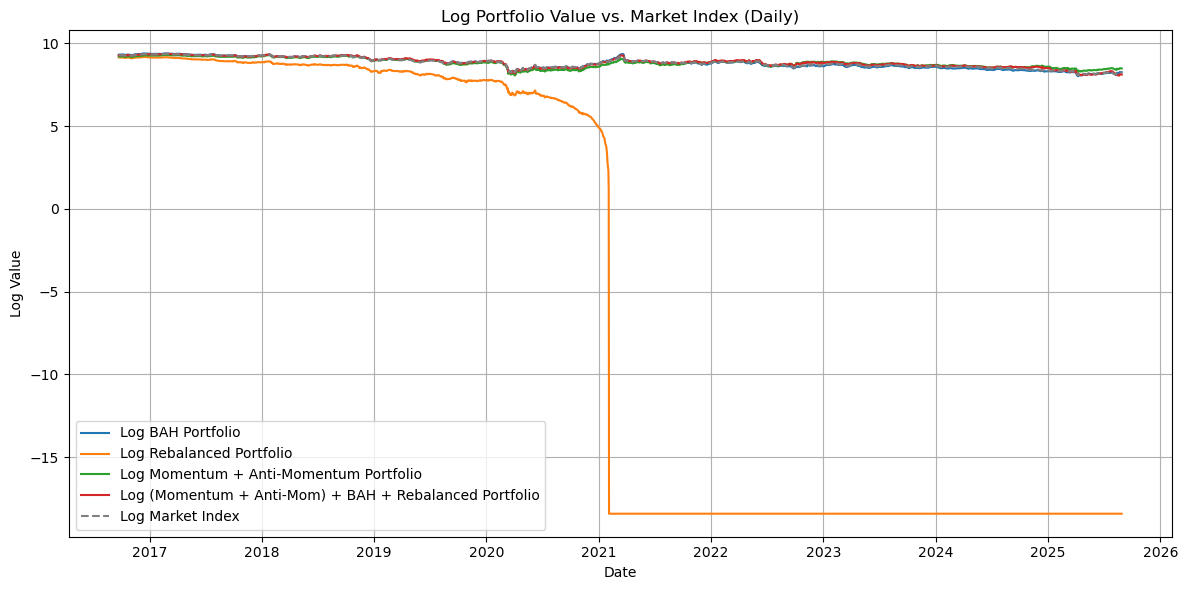

In [18]:
# === PLOT 1: Log Portfolio Values ===
plt.figure(figsize=(12, 6))
plt.plot(np.log(bah.run()[0][252:]), label="Log BAH Portfolio")
plt.plot(np.log(rebal.run()[0][252:].clip(lower=1e-8)), label="Log Rebalanced Portfolio")
plt.plot(np.log(agg_value1[252:]), label="Log Momentum + Anti-Momentum Portfolio")
#plt.plot(np.log(agg_value2), label="Log (Momentum + Anti-Momentum) + BAH Portfolio")
#plt.plot(np.log(agg_value3), label="Log (Momentum + Anti-Momentum) + Rebalanced Portfolio")
#plt.plot(np.log(agg_value4), label="Log BAH + Rebalanced Portfolio")
plt.plot(np.log(agg_value5[252:]), label="Log (Momentum + Anti-Mom) + BAH + Rebalanced Portfolio")
plt.plot(np.log(market_index[252:]), label="Log Market Index", linestyle="--", color="gray")
#plt.plot(np.log(mom.run()[0][252:]), label="Log Momentum")
#plt.plot(np.log(anti.run()[0][252:]), label="Log Anti-Momentum")
plt.legend()
plt.title("Log Portfolio Value vs. Market Index (Daily)")
plt.xlabel("Date")
plt.ylabel("Log Value")
plt.grid(True)
plt.tight_layout()
plt.show()


Text(0.5, 0, 'Time')

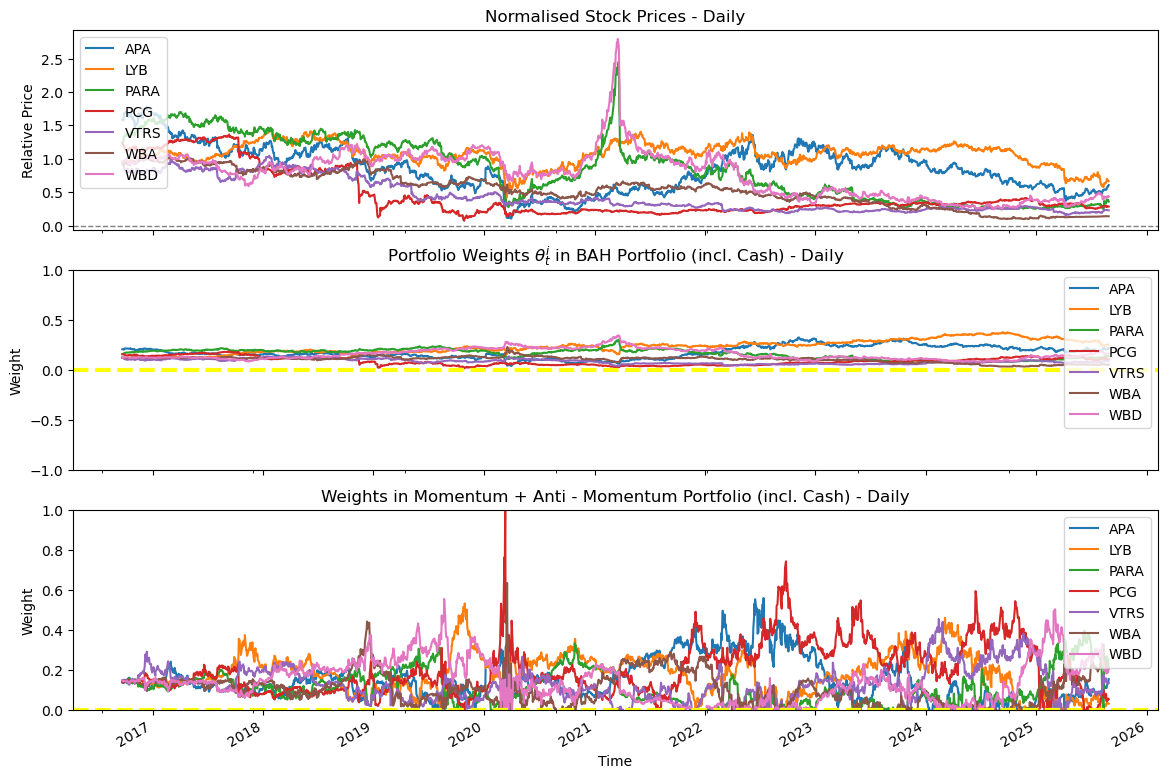

In [19]:
# === PLOT 2: Plot of theta time series against individual stock prices ===

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Top plot: normalized stock prices
normalized[252:].plot(ax=ax1)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)  
ax1.set_title("Normalised Stock Prices - Daily")
ax1.set_ylabel("Relative Price")
ax1.legend(loc="upper left")

# Middle plot: theta values BAH + cash position
theta[252:].plot(ax=ax2)
ax2.axhline(0, color='yellow', linestyle='--', linewidth=3)  
ax2.set_title(r"Portfolio Weights $\theta_{t}^i$ in BAH Portfolio (incl. Cash) - Daily")
ax2.set_ylabel("Weight")
ax2.set_ylim(-1, 1)
ax2.legend(loc="upper right")
ax2.set_xlabel("Time")

# Middle plot: momentum and anti-momentum weights + cash position
agg_weights1[252:].plot(ax=ax3)
ax3.axhline(0, color='yellow', linestyle='--', linewidth=3)  
ax3.set_title(r"Weights in Momentum + Anti - Momentum Portfolio (incl. Cash) - Daily")
ax3.set_ylabel("Weight")
ax3.set_ylim(0, 1)
ax3.legend(loc="upper right")
ax3.set_xlabel("Time")

# plt.tight_layout()
# plt.show()


In [20]:
# === Compute MDD (maximal drawdown) ===
def compute_max_drawdown(series):
    running_max = series.cummax()
    drawdown = (series - running_max) / running_max
    max_drawdown = drawdown.min()
    return max_drawdown

In [21]:
# === Compute MDD of each portfolio ===
mdd_bah = compute_max_drawdown(bah.run()[0])
mdd_rebalanced = compute_max_drawdown(rebal.run()[0])
mdd_momentum = compute_max_drawdown(agg_value1)
mdd_bah_mam = compute_max_drawdown(agg_value2)
mdd_crp_mam = compute_max_drawdown(agg_value3)
mdd_bah_crp = compute_max_drawdown(agg_value4)
mdd_aggregated = compute_max_drawdown(agg_value5)
mdd_market = compute_max_drawdown(market_index)

In [22]:
print(f"Max Drawdown (BAH):                       {mdd_bah:.2%}")
print(f"Max Drawdown (Rebalanced):                {mdd_rebalanced:.2%}")
print(f"Max Drawdown (Momentum + Anti-Momentum):  {mdd_momentum:.2%}")
#print(f"Max Drawdown (M+AM+BAH):                  {mdd_bah_mam:.2%}")
#print(f"Max Drawdown (M+AM+CRP):                  {mdd_crp_mam:.2%}")
#print(f"Max Drawdown (BAH+CRP):                   {mdd_bah_crp:.2%}")
print(f"Max Drawdown (Aggregated):                {mdd_aggregated:.2%}")
print(f"Max Drawdown (Market):                    {mdd_market:.2%}")

Max Drawdown (BAH):                       -74.89%
Max Drawdown (Rebalanced):                -164.19%
Max Drawdown (Momentum + Anti-Momentum):  -71.55%
Max Drawdown (Aggregated):                -73.52%
Max Drawdown (Market):                    -72.89%


In [23]:
# === Compute Sharpe Ratio for each portfolio ===
def compute_sharpe_ratio(portfolio_values, risk_free_rate=0.0, freq_per_year=252, annualize=True):
    """
    Computes the Sharpe ratio for a portfolio.

    Parameters:
    - portfolio_values (pd.Series): Portfolio value over time (indexed by date).
    - risk_free_rate (float): Risk-free rate per year (e.g., 0.02 for 2%). Default is 0.
    - freq_per_year (int): Number of periods per year (52 for weekly, 252 for daily, 12 for monthly).
    - annualize (bool): Whether to return the annualized Sharpe ratio.

    Returns:
    - Sharpe ratio (float)
    """
    returns = portfolio_values.pct_change().dropna()

    # Convert annual risk-free rate to per-period rate
    rf_per_period = (1 + risk_free_rate) ** (1 / freq_per_year) - 1

    # Excess returns
    excess_returns = returns - rf_per_period

    # Sharpe ratio (non-annualized)
    sharpe = excess_returns.mean() / excess_returns.std()

    if annualize:
        sharpe *= np.sqrt(freq_per_year)

    return sharpe


In [24]:
sharpe_bah = compute_sharpe_ratio(bah.run()[0])
sharpe_rebalanced = compute_sharpe_ratio(rebal.run()[0])
sharpe_momentum = compute_sharpe_ratio(agg_value1)
sharpe_bah_mam = compute_sharpe_ratio(agg_value2)
sharpe_crp_mam = compute_sharpe_ratio(agg_value3)
sharpe_bah_crp = compute_sharpe_ratio(agg_value4)
sharpe_aggregated = compute_sharpe_ratio(agg_value5)
sharpe_market = compute_sharpe_ratio(market_index)

print(f"Sharpe Ratio (BAH):                          {sharpe_bah:.2f}")
print(f"Sharpe Ratio (Rebalanced):                   {sharpe_rebalanced:.2f}")
print(f"Sharpe Ratio (Momentum + Anti-Momentum):     {sharpe_momentum:.2f}")
#print(f"Sharpe Ratio (M+AM+BAH):                     {sharpe_bah_mam:.2f}")
#print(f"Sharpe Ratio (M+AM+CRP):                     {sharpe_crp_mam:.2f}")
#print(f"Sharpe Ratio (BAH+CRP):                      {sharpe_bah_crp:.2f}")
print(f"Sharpe Ratio (Aggregated):                   {sharpe_aggregated:.2f}")
print(f"Sharpe Ratio (Market):                       {sharpe_market:.2f}")


Sharpe Ratio (BAH):                          -0.20
Sharpe Ratio (Rebalanced):                   -0.07
Sharpe Ratio (Momentum + Anti-Momentum):     -0.13
Sharpe Ratio (Aggregated):                   -0.26
Sharpe Ratio (Market):                       -0.23
